<a href="https://colab.research.google.com/github/Dennischegemwangi/code-base/blob/main/Text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
all_datasets = list(api.list_datasets())
print(f"Total datasets: {len(all_datasets)}")

In [6]:
from datasets import load_dataset
emotions = load_dataset("dair-ai/emotion")

train_ds = emotions["train"]
train_ds[0]

#print (train_ds.features)
print (train_ds["text"][ :5])

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy']


In [7]:
#Dataset preprocessing (Data frame)
import pandas as pd
emotions.set_format(type = "pandas")
df = emotions["train"][ : ]
df.tail()

,text,label
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,1
15998,i feel like this was such a rude comment and i...,3
15999,i know a lot but i feel so stupid because i ca...,0


In [8]:
#converting labels to string
def label_int2str(row):
    return emotions ["train"].features["label"].int2str(row)


df["label_name"] = df["label"].apply(label_int2str)
df.head()

,text,label,label_name
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


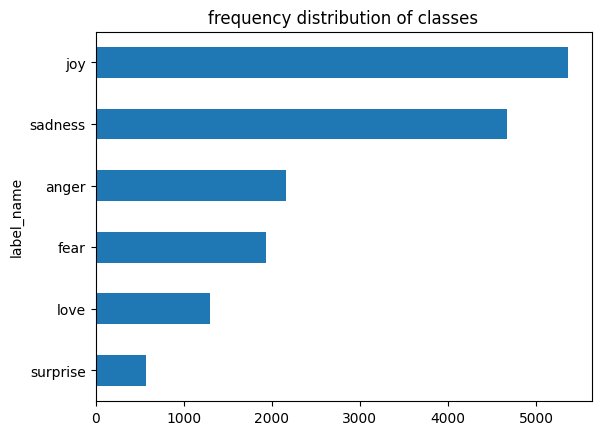

In [9]:
#identifying class distribution

import  matplotlib.pyplot as plt

df["label_name"]. value_counts(ascending=True).plot.barh()
plt.title("frequency distribution of classes")
plt.show()

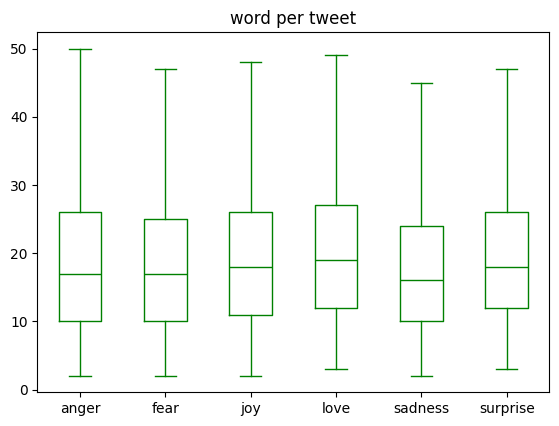

In [10]:
#number of token per label

df["word per tweet"] = df["text"].str.split().apply(len)
df.boxplot("word per tweet",by= "label_name",grid = False,showfliers= False,color ="green")
plt.suptitle("")
plt.xlabel("")
plt.show()

In [ ]:
emotions.reset_format()

In [11]:
#character tokenization
text = "Tokenization is a crucial step in NLP "
tokenized_txt = list(text)
print(tokenized_txt)

#encoding

token2idx = {ch: idx for idx, ch in enumerate(sorted(set(tokenized_txt)))}

print(token2idx)
input_ids = [token2idx[token] for token in tokenized_txt]
print(input_ids)

['T', 'o', 'k', 'e', 'n', 'i', 'z', 'a', 't', 'i', 'o', 'n', ' ', 'i', 's', ' ', 'a', ' ', 'c', 'r', 'u', 'c', 'i', 'a', 'l', ' ', 's', 't', 'e', 'p', ' ', 'i', 'n', ' ', 'N', 'L', 'P', ' ']
{' ': 0, 'L': 1, 'N': 2, 'P': 3, 'T': 4, 'a': 5, 'c': 6, 'e': 7, 'i': 8, 'k': 9, 'l': 10, 'n': 11, 'o': 12, 'p': 13, 'r': 14, 's': 15, 't': 16, 'u': 17, 'z': 18}
[4, 12, 9, 7, 11, 8, 18, 5, 16, 8, 12, 11, 0, 8, 15, 0, 5, 0, 6, 14, 17, 6, 8, 5, 10, 0, 15, 16, 7, 13, 0, 8, 11, 0, 2, 1, 3, 0]


In [ ]:
#One hot-encoding
import  torch
import torch.nn.functional as F
input_ids = torch.tensor(input_ids)
one_hot_encoding =  F.one_hot(input_ids,num_classes = len(token2idx))
one_hot_encoding.shape


print(f"tokenizer index: {tokenized_txt[0]}")
print( f"tensor index : {input_ids[0]}")
print(f"one hot : {one_hot_encoding[0]}")

tokenizer index: T
tensor index : 4
one hot : tensor([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


/tmp/ipykernel_1267/723678177.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  input_ids = torch.tensor(input_ids)


In [12]:
#subword Tokenization
from transformers import AutoTokenizer
model_ckpt = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
encoded_txt = tokenizer(text)

print(encoded_txt)

#converting ids back to tokens
tokens = tokenizer.convert_ids_to_tokens(encoded_txt.input_ids)
print(tokens)
#converting tokens back to string
print(tokenizer.convert_tokens_to_string(tokens))
# model's vocabulary size
tokenizer.vocab_size
#model's context size
tokenizer.model_max_length

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

{'input_ids': [101, 19204, 3989, 2003, 1037, 10232, 3357, 1999, 17953, 2361, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
['[CLS]', 'token', '##ization', 'is', 'a', 'crucial', 'step', 'in', 'nl', '##p', '[SEP]']
[CLS] tokenization is a crucial step in nlp [SEP]


512

In [ ]:
#Tokenizing a dataset
def tokenize(batch):
    return tokenizer(batch["text"],padding = True,truncation = True)

#print (tokenize(emotions["train"][ :2]))
My_data = tokenizer (emotions["train"][ :2])
My_token = tokenizer.convert_ids_to_tokens(my_data.input_ids)
print(my_data)